# Import The Important Libraries and Packages

In [ ]:
from google.colab import drive

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler, FunctionTransformer, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import classification_report, roc_curve, auc

# Loading the dataset

In [ ]:
drive.mount('/content/drive')
path = "/content/drive/MyDrive/Colab Notebooks/Census Income"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
data = pd.read_csv(f"{path}/Adult Census Income.csv")
data

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,<=50K
32557,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32558,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32559,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K


# Understanding Features

- age > Age of the person in years.
- workclass > Type of employer
  - Private (Employee of a private-sector company), Self-emp-not-inc (Self-employed, business not incorporated), Self-emp-inc (Self-employed, business incorporated), Federal-gov, Local-gov, State-gov, Without-pay (Unpaid work, such as helping in a family business), Never-worked.
  - Missing values are marked ?.
- fnlwgt > (“Final weight”) the number of people in the population that this row represents, assigned by the Census Bureau. It is a sampling weight, not a personal attribute, and is often dropped for modeling.
- education > Highest education level reached
  - Bachelors, HS-grad, Masters, Doctorate, Some-college, etc.
- education.num	> The same information as education, encoded as an ordinal number
  - e.g., 9 = HS-grad, 13 = Bachelors, 16 = Doctorate
  - It is redundant with education, so keep only one of them.
- marital.status > Married-civ-spouse, Divorced, Never-married, Separated, Widowed, Married-spouse-absent, Married-AF-spouse.
- occupation > Job type
  - Tech-support, Craft-repair, Sales, Exec-managerial, Prof-specialty, Handlers-cleaners, Adm-clerical, etc.
  - Contains missing values (?).
- relationship > Role in the household
  - Wife, Husband, Own-child, Not-in-family, Other-relative, Unmarried.
- race > White, Black, Asian-Pac-Islander, Amer-Indian-Eskimo, Other.
- capital.gain > Numeric	Income from investments or asset sales (profit)
  - Very skewed, mostly 0.
- capital.loss > Numeric	Losses from investments or asset sales
  - Also very skewed, mostly 0.
- hours.per.week > Numeric Hours worked per week.
- native.country > Country of origin (about 90% United-States).
  - Has missing values (?).
- income	(Target) > <=50K or >50K.

# inspection and cleaning

Questions
1. How many rows and columns are in the dataset?
2. What are the data types of the features?
3. Are there any duplicate rows?
4. Which columns contain missing values?
5. What is the target variable?

Required visualizations
- Bar chart: distribution of the target variable (income).
- Bar chart: number of missing values per column.

In [ ]:
data.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


data describtion

In [ ]:
data.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


data types and info

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [ ]:
features = data.columns.tolist()
features

['age',
 'workclass',
 'fnlwgt',
 'education',
 'education.num',
 'marital.status',
 'occupation',
 'relationship',
 'race',
 'sex',
 'capital.gain',
 'capital.loss',
 'hours.per.week',
 'native.country',
 'income']

In [ ]:
numerical_features = ['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']
categorical_features = ['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country', 'income']

number of rows and columns

In [ ]:
data.shape

(32561, 15)

columns name

num of duplicate rows

In [ ]:
data.duplicated().sum()

np.int64(24)

In [ ]:
data_copy = data.copy()

In [ ]:
data_copy.drop_duplicates().shape

(32537, 15)

In [ ]:
data_copy.reset_index(drop=True, inplace=True)

missing values in columns

In [ ]:
data_copy = data_copy.apply(lambda col: col.str.strip() if col.dtype  == 'object' else col)
print((data_copy == '?').sum())
data_copy.replace('?', np.nan, inplace=True)
print(data_copy.isnull().sum())

age                  0
workclass         1836
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
native.country     583
income               0
dtype: int64
age                  0
workclass         1836
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
native.country     583
income               0
dtype: int64


In [ ]:
(data_copy.isnull().any(axis=1).sum() / len(data)) * 100

np.float64(7.367709836921471)

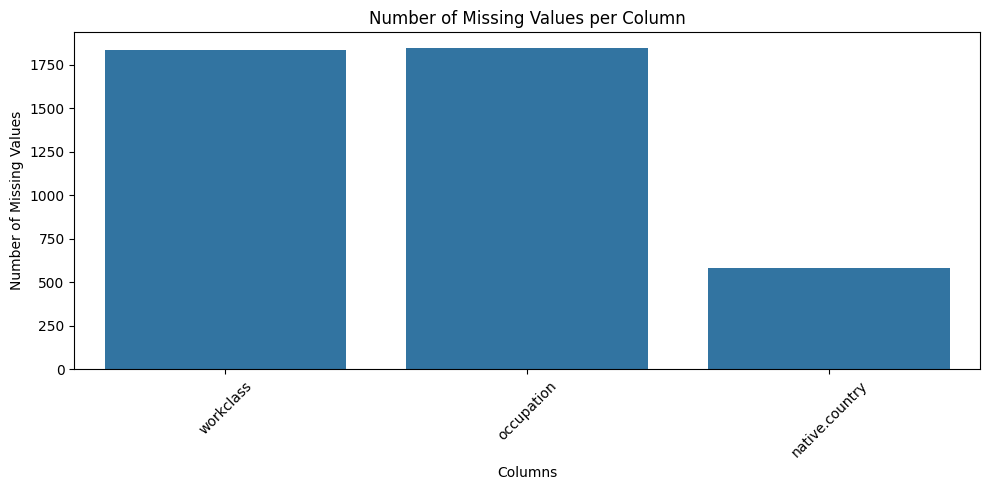

In [ ]:
missing_values = data_copy.isnull().sum()
missing_values = missing_values[missing_values > 0]

plt.figure(figsize=(10, 5))
sns.barplot(x=missing_values.index, y=missing_values.values)

plt.title('Number of Missing Values per Column')
plt.xlabel('Columns')
plt.ylabel('Number of Missing Values')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

target values

In [ ]:
data['income'].unique()

array(['<=50K', '>50K'], dtype=object)

In [ ]:
data['income'].value_counts()

,count
income,
<=50K,24720
>50K,7841


 distribution of the target variable (income)

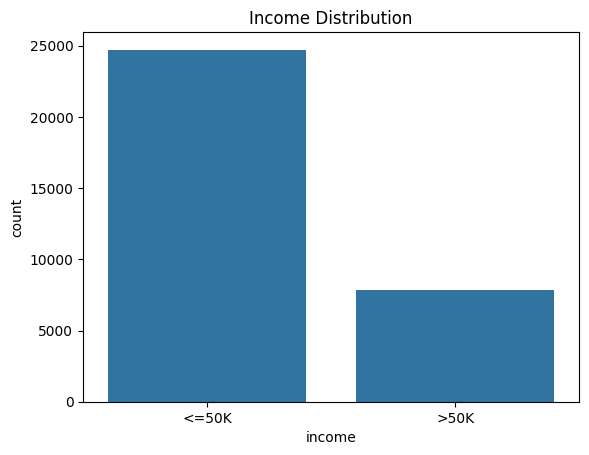

In [ ]:
sns.countplot(data=data, x='income')
plt.title('Income Distribution')
plt.show()

In [ ]:
for col in data_copy.select_dtypes(include='object').columns:
    print(f"\n{col}:")
    print(data_copy[col].unique())


workclass:
[nan 'Private' 'State-gov' 'Federal-gov' 'Self-emp-not-inc' 'Self-emp-inc'
 'Local-gov' 'Without-pay' 'Never-worked']

education:
['HS-grad' 'Some-college' '7th-8th' '10th' 'Doctorate' 'Prof-school'
 'Bachelors' 'Masters' '11th' 'Assoc-acdm' 'Assoc-voc' '1st-4th' '5th-6th'
 '12th' '9th' 'Preschool']

marital.status:
['Widowed' 'Divorced' 'Separated' 'Never-married' 'Married-civ-spouse'
 'Married-spouse-absent' 'Married-AF-spouse']

occupation:
[nan 'Exec-managerial' 'Machine-op-inspct' 'Prof-specialty'
 'Other-service' 'Adm-clerical' 'Craft-repair' 'Transport-moving'
 'Handlers-cleaners' 'Sales' 'Farming-fishing' 'Tech-support'
 'Protective-serv' 'Armed-Forces' 'Priv-house-serv']

relationship:
['Not-in-family' 'Unmarried' 'Own-child' 'Other-relative' 'Husband' 'Wife']

race:
['White' 'Black' 'Asian-Pac-Islander' 'Other' 'Amer-Indian-Eskimo']

sex:
['Female' 'Male']

native.country:
['United-States' nan 'Mexico' 'Greece' 'Vietnam' 'China' 'Taiwan' 'India'
 'Philippines' 'Tr

In [ ]:
data_copy.select_dtypes(include='number').lt(0).sum()

,0
age,0
fnlwgt,0
education.num,0
capital.gain,0
capital.loss,0
hours.per.week,0


## Insights
1. How are missing values represented in the dataset (NaN, ?, ...)?
- The missing values in the Adult Census Income dataset are represented by the ? symbol rather than standard NaN values. They appear mainly in categorical columns such as workclass, occupation, and native.country.
2. Should missing values be removed or filled?
- we found that approximately 7.37% of the rows contain missing values. Removing these rows would result in losing around 2,399 records, which could lead to information loss.
- Therefore, we chose Most Frequent Imputation using SimpleImputer(strategy='most_frequent') to replace missing values with the most frequently occurring category in each column.
- To avoid data leakage, the imputer is fitted on the training set only and then applied to both training and testing sets.

3. Are there any suspicious values in the dataset?
- some suspicious values were identified in the categorical features, particularly in the native.country column. Examples include Columbia instead of Colombia, Trinadad&Tobago instead of Trinidad&Tobago, and incomplete values such as Hong and South.
- These values may indicate spelling inconsistencies or incomplete category names and should be reviewed before further processing.
- Regarding numerical features, no negative values were found. Outlier detection and analysis will be performed separately in the next stage.

# Handling Messing Values

## workclass

In [ ]:
data_copy[data_copy['workclass'].isnull()]

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,<=50K
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,<=50K
14,51,NaN,172175,Doctorate,16,Never-married,NaN,Not-in-family,White,Male,0,2824,40,United-States,>50K
24,61,NaN,135285,HS-grad,9,Married-civ-spouse,NaN,Husband,White,Male,0,2603,32,United-States,<=50K
44,71,NaN,100820,HS-grad,9,Married-civ-spouse,NaN,Husband,White,Male,0,2489,15,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32533,35,NaN,320084,Bachelors,13,Married-civ-spouse,NaN,Wife,White,Female,0,0,55,United-States,>50K
32534,30,NaN,33811,Bachelors,13,Never-married,NaN,Not-in-family,Asian-Pac-Islander,Female,0,0,99,United-States,<=50K
32541,71,NaN,287372,Doctorate,16,Married-civ-spouse,NaN,Husband,White,Male,0,0,10,United-States,>50K
32543,41,NaN,202822,HS-grad,9,Separated,NaN,Not-in-family,Black,Female,0,0,32,United-States,<=50K


In [ ]:
data_copy[data_copy['occupation'].isnull()]

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,<=50K
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,<=50K
14,51,NaN,172175,Doctorate,16,Never-married,NaN,Not-in-family,White,Male,0,2824,40,United-States,>50K
24,61,NaN,135285,HS-grad,9,Married-civ-spouse,NaN,Husband,White,Male,0,2603,32,United-States,<=50K
44,71,NaN,100820,HS-grad,9,Married-civ-spouse,NaN,Husband,White,Male,0,2489,15,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32533,35,NaN,320084,Bachelors,13,Married-civ-spouse,NaN,Wife,White,Female,0,0,55,United-States,>50K
32534,30,NaN,33811,Bachelors,13,Never-married,NaN,Not-in-family,Asian-Pac-Islander,Female,0,0,99,United-States,<=50K
32541,71,NaN,287372,Doctorate,16,Married-civ-spouse,NaN,Husband,White,Male,0,0,10,United-States,>50K
32543,41,NaN,202822,HS-grad,9,Separated,NaN,Not-in-family,Black,Female,0,0,32,United-States,<=50K


In [ ]:
both = (data_copy['workclass'].isnull()) & (data_copy['occupation'].isnull())
data_copy[both]

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,<=50K
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,<=50K
14,51,NaN,172175,Doctorate,16,Never-married,NaN,Not-in-family,White,Male,0,2824,40,United-States,>50K
24,61,NaN,135285,HS-grad,9,Married-civ-spouse,NaN,Husband,White,Male,0,2603,32,United-States,<=50K
44,71,NaN,100820,HS-grad,9,Married-civ-spouse,NaN,Husband,White,Male,0,2489,15,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32533,35,NaN,320084,Bachelors,13,Married-civ-spouse,NaN,Wife,White,Female,0,0,55,United-States,>50K
32534,30,NaN,33811,Bachelors,13,Never-married,NaN,Not-in-family,Asian-Pac-Islander,Female,0,0,99,United-States,<=50K
32541,71,NaN,287372,Doctorate,16,Married-civ-spouse,NaN,Husband,White,Male,0,0,10,United-States,>50K
32543,41,NaN,202822,HS-grad,9,Separated,NaN,Not-in-family,Black,Female,0,0,32,United-States,<=50K


In [ ]:
print("Before Droping")
print(data_copy['income'].value_counts(normalize=True)* 100)
print("After Droping")
print(data_copy[~both]['income'].value_counts(normalize=True)* 100)

Before Droping
income
<=50K    75.919044
>50K     24.080956
Name: proportion, dtype: float64
After Droping
income
<=50K    75.101709
>50K     24.898291
Name: proportion, dtype: float64


In [ ]:
data_copy = data_copy.dropna(subset=['workclass']).reset_index(drop=True)
data_copy

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
1,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
2,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K
3,34,Private,216864,HS-grad,9,Divorced,Other-service,Unmarried,White,Female,0,3770,45,United-States,<=50K
4,38,Private,150601,10th,6,Separated,Adm-clerical,Unmarried,White,Male,0,3770,40,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30720,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,<=50K
30721,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
30722,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
30723,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K


## occupation

In [ ]:
data_copy[data_copy['occupation'].isnull()]

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
8373,18,Never-worked,206359,10th,6,Never-married,NaN,Own-child,White,Male,0,0,40,United-States,<=50K
12921,23,Never-worked,188535,7th-8th,4,Divorced,NaN,Not-in-family,White,Male,0,0,35,United-States,<=50K
16148,17,Never-worked,237272,10th,6,Never-married,NaN,Own-child,White,Male,0,0,30,United-States,<=50K
20722,18,Never-worked,157131,11th,7,Never-married,NaN,Own-child,White,Female,0,0,10,United-States,<=50K
23131,20,Never-worked,462294,Some-college,10,Never-married,NaN,Own-child,Black,Male,0,0,40,United-States,<=50K
30509,30,Never-worked,176673,HS-grad,9,Married-civ-spouse,NaN,Wife,Black,Female,0,0,40,United-States,<=50K
30515,18,Never-worked,153663,Some-college,10,Never-married,NaN,Own-child,White,Male,0,0,4,United-States,<=50K


In [ ]:
data_copy[data_copy['workclass'] == 'Never-worked']

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
8373,18,Never-worked,206359,10th,6,Never-married,NaN,Own-child,White,Male,0,0,40,United-States,<=50K
12921,23,Never-worked,188535,7th-8th,4,Divorced,NaN,Not-in-family,White,Male,0,0,35,United-States,<=50K
16148,17,Never-worked,237272,10th,6,Never-married,NaN,Own-child,White,Male,0,0,30,United-States,<=50K
20722,18,Never-worked,157131,11th,7,Never-married,NaN,Own-child,White,Female,0,0,10,United-States,<=50K
23131,20,Never-worked,462294,Some-college,10,Never-married,NaN,Own-child,Black,Male,0,0,40,United-States,<=50K
30509,30,Never-worked,176673,HS-grad,9,Married-civ-spouse,NaN,Wife,Black,Female,0,0,40,United-States,<=50K
30515,18,Never-worked,153663,Some-college,10,Never-married,NaN,Own-child,White,Male,0,0,4,United-States,<=50K


In [ ]:
mask = data_copy['workclass'] == 'Never-worked'
data_copy.loc[mask, 'occupation'] = 'no-work'

In [ ]:
data_copy[data_copy['workclass'] == 'Never-worked']

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
8373,18,Never-worked,206359,10th,6,Never-married,no-work,Own-child,White,Male,0,0,40,United-States,<=50K
12921,23,Never-worked,188535,7th-8th,4,Divorced,no-work,Not-in-family,White,Male,0,0,35,United-States,<=50K
16148,17,Never-worked,237272,10th,6,Never-married,no-work,Own-child,White,Male,0,0,30,United-States,<=50K
20722,18,Never-worked,157131,11th,7,Never-married,no-work,Own-child,White,Female,0,0,10,United-States,<=50K
23131,20,Never-worked,462294,Some-college,10,Never-married,no-work,Own-child,Black,Male,0,0,40,United-States,<=50K
30509,30,Never-worked,176673,HS-grad,9,Married-civ-spouse,no-work,Wife,Black,Female,0,0,40,United-States,<=50K
30515,18,Never-worked,153663,Some-college,10,Never-married,no-work,Own-child,White,Male,0,0,4,United-States,<=50K


## native.country

In [ ]:
data_copy[data_copy['native.country'].isnull()]

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
7,41,Private,70037,Some-college,10,Never-married,Craft-repair,Unmarried,White,Male,0,3004,60,NaN,>50K
15,22,Private,119592,Assoc-acdm,12,Never-married,Handlers-cleaners,Not-in-family,Black,Male,0,2824,40,NaN,>50K
58,60,Self-emp-inc,226355,Assoc-voc,11,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,2415,70,NaN,>50K
78,39,Self-emp-not-inc,218490,Prof-school,15,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,2415,50,NaN,>50K
79,43,Federal-gov,156996,Prof-school,15,Married-civ-spouse,Prof-specialty,Husband,Asian-Pac-Islander,Male,0,2415,55,NaN,>50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30602,45,Private,199590,5th-6th,3,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,NaN,<=50K
30632,44,Self-emp-inc,71556,Masters,14,Married-civ-spouse,Sales,Husband,White,Male,0,0,50,NaN,>50K
30649,58,Self-emp-inc,181974,Doctorate,16,Never-married,Prof-specialty,Not-in-family,White,Female,0,0,99,NaN,<=50K
30669,42,Self-emp-not-inc,217597,HS-grad,9,Divorced,Sales,Own-child,White,Male,0,0,50,NaN,<=50K


In [ ]:
data_copy['native.country'].value_counts()

,count
native.country,
United-States,27511
Mexico,610
Philippines,188
Germany,128
Puerto-Rico,109
Canada,107
El-Salvador,100
India,100
Cuba,92


In [ ]:
print("Before Dropping")
print(data_copy['income'].value_counts(normalize=True))
print("After Dropping")
print(data_copy[data_copy['native.country'].notnull()]['income'].value_counts(normalize=True))

Before Dropping
income
<=50K    0.751017
>50K     0.248983
Name: proportion, dtype: float64
After Dropping
income
<=50K    0.751135
>50K     0.248865
Name: proportion, dtype: float64


In [ ]:
data_copy = data_copy.dropna(subset=['native.country']).reset_index(drop=True)
data_copy

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
1,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
2,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K
3,34,Private,216864,HS-grad,9,Divorced,Other-service,Unmarried,White,Female,0,3770,45,United-States,<=50K
4,38,Private,150601,10th,6,Separated,Adm-clerical,Unmarried,White,Male,0,3770,40,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30164,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,<=50K
30165,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
30166,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
30167,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K


## Check dataset after handling the null values

In [ ]:
data_copy.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education.num,0
marital.status,0
occupation,0
relationship,0
race,0
sex,0


# Feature selection and transformation
Questions
1. Are there any outliers in numerical features?

- outliers were detected in all numerical features using the IQR method. However, not all detected outliers represent incorrect values.
- The capital.gain and capital.loss features are highly right-skewed, with 75% of their values equal to zero. The education.num feature represents discrete educational levels, while extreme values in age and hours.per.week may represent valid observations.
- Therefore, the detected outliers should not be removed automatically, as they may contain valuable information.

3. Should you use One-Hot Encoding for categorical features?

- One-Hot Encoding is suitable for most categorical features because they represent nominal categories without a natural order. The education column will be removed because education.num provides a numerical representation of the same educational information.
- The native.country feature contains many categories with highly imbalanced frequencies. Therefore, rare categories with fewer than 50 occurrences in the training set will be grouped into an Other category before applying One-Hot Encoding. This reduces the number of resulting features while preserving the most frequent categories.

4. Are there any highly correlated features?
- The correlation matrix shows that there are no highly correlated numerical features.
- All correlation coefficients between different numerical features are relatively weak.
- The highest positive correlation is between education.num and hours.per.week (0.148).
- No pair of features has an absolute correlation coefficient greater than 0.8.
- Conclusion: No numerical features need to be removed based on correlation analysis alone.
5. Are there any redundant features?
- only between education and education.num
6. Is the target variable balanced?
- No. The `<=50K` class has about 3 times as many records as `>50K` (about 76% vs 24%), so the target is imbalanced.

Required visualizations
- Box plots: numerical features to inspect outliers.
- Histograms: numerical feature distributions before scaling.
- Correlation heatmap: numerical features.

### Numerical Features - Key Observations

- **age:** Slightly right-skewed, with most observations concentrated between 20 and 50.
- **education.num:** Discrete numerical feature with values concentrated around specific education levels.
- **capital.gain:** Highly right-skewed, with most observations equal to zero and a few extremely large values.
- **capital.loss:** Highly right-skewed, with most observations equal to zero and some outliers.
- **hours.per.week:** Most observations are concentrated at 40 hours per week, with more than 15,000–16,000 occurrences, representing the typical full-time working schedule.
### Preprocessing Decisions

- Feature scaling will likely be required for scale-sensitive models.
- RobustScaler will be considered due to the presence of outliers.
- Log transformation may be considered for capital.gain and capital.loss to reduce skewness.
- Outliers will not be removed without further investigation.
- The final preprocessing techniques will depend on the selected machine learning models.

Visualizing Outliers using box plots

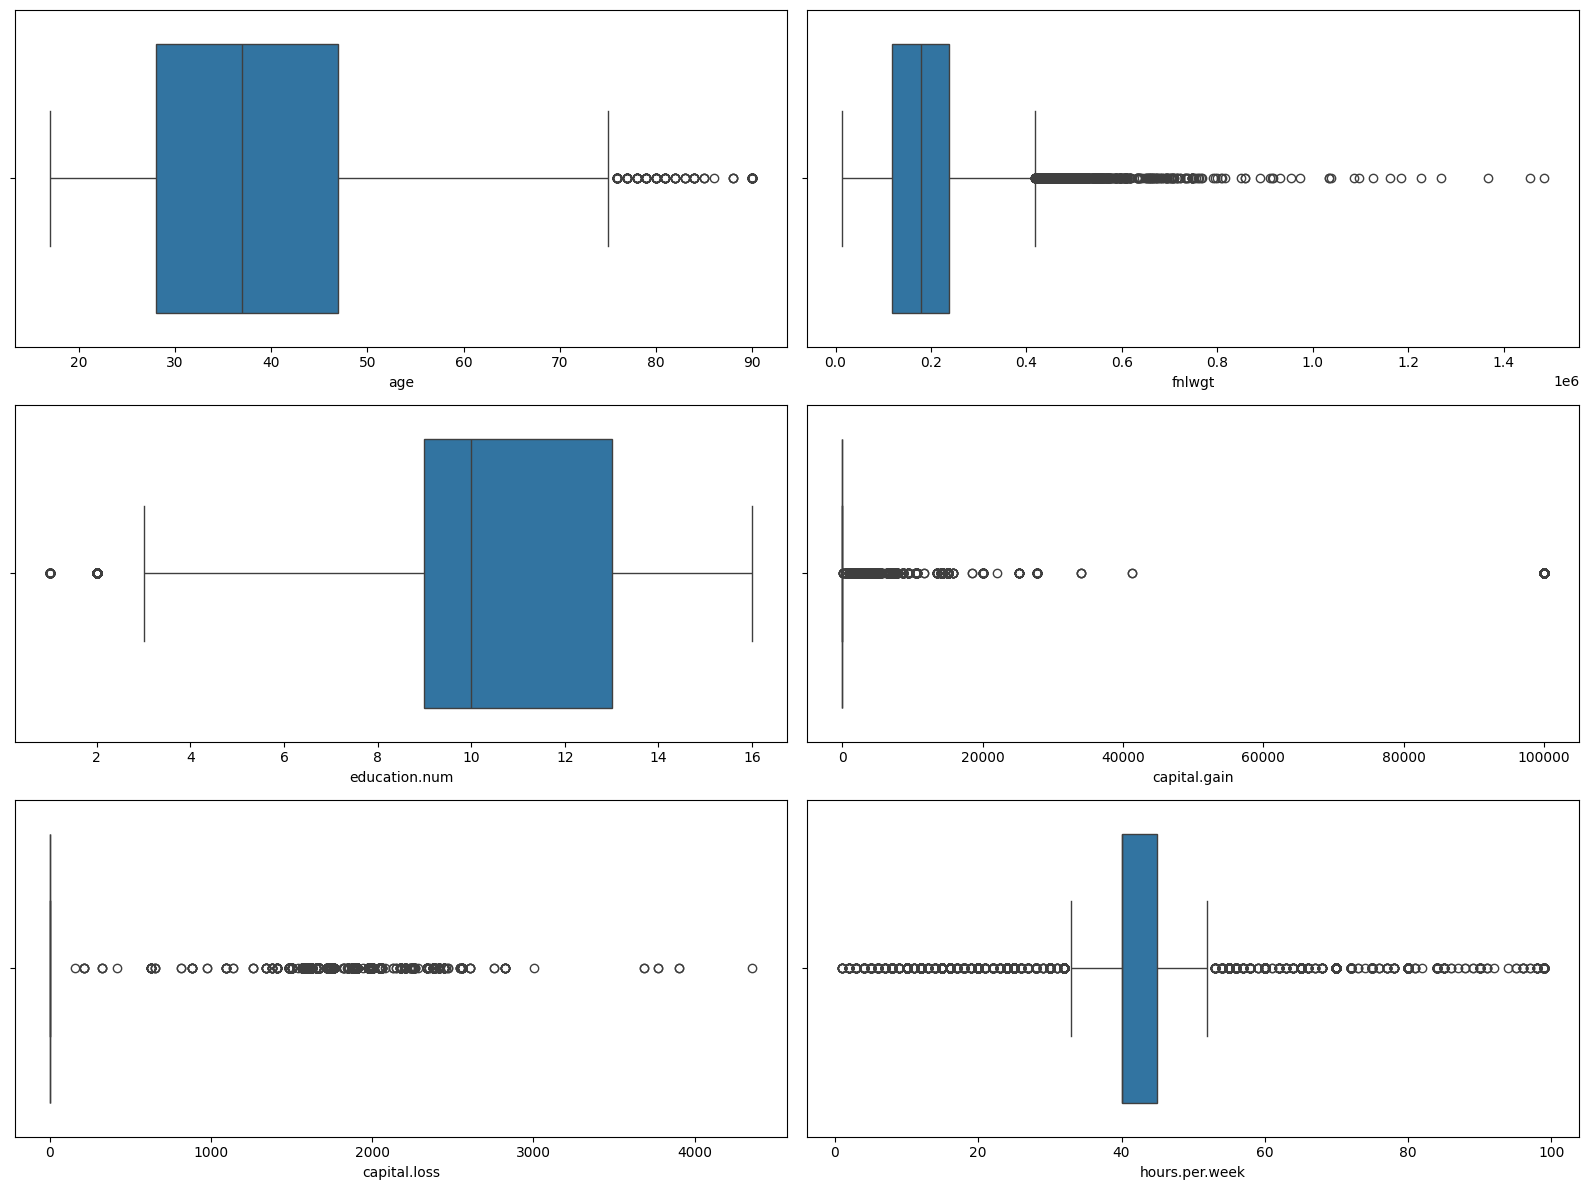

In [ ]:
fig, axes = plt.subplots(3,2,figsize=(16, 12))
for i, col in enumerate(numerical_features):
  ax = axes.flat[i]
  sns.boxplot(x=data_copy[col], ax=ax)
plt.tight_layout()
plt.show()

Number of outliers

In [ ]:
for col in numerical_features:
  Q1 = data_copy[col].quantile(0.25)
  Q3 = data_copy[col].quantile(0.75)
  IQR = Q3 - Q1
  lower = Q1 - 1.5 * IQR
  upper = Q3 + 1.5 * IQR
  outliers = data_copy[
      (data_copy[col] < lower) |
      (data_copy[col] > upper)
  ]
  print(f'{col}: {len(outliers)} outliers')

age: 169 outliers
fnlwgt: 904 outliers
education.num: 196 outliers
capital.gain: 2538 outliers
capital.loss: 1427 outliers
hours.per.week: 7956 outliers


In [ ]:
data_copy[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
age,30169.0,38.433757,13.136121,17.0,28.0,37.0,47.0,90.0
fnlwgt,30169.0,189802.232291,105653.158358,13769.0,117634.0,178429.0,237624.0,1484705.0
education.num,30169.0,10.120687,2.550235,1.0,9.0,10.0,13.0,16.0
capital.gain,30169.0,1091.754483,7405.505862,0.0,0.0,0.0,0.0,99999.0
capital.loss,30169.0,88.351984,404.253703,0.0,0.0,0.0,0.0,4356.0
hours.per.week,30169.0,40.928337,11.982022,1.0,40.0,40.0,45.0,99.0


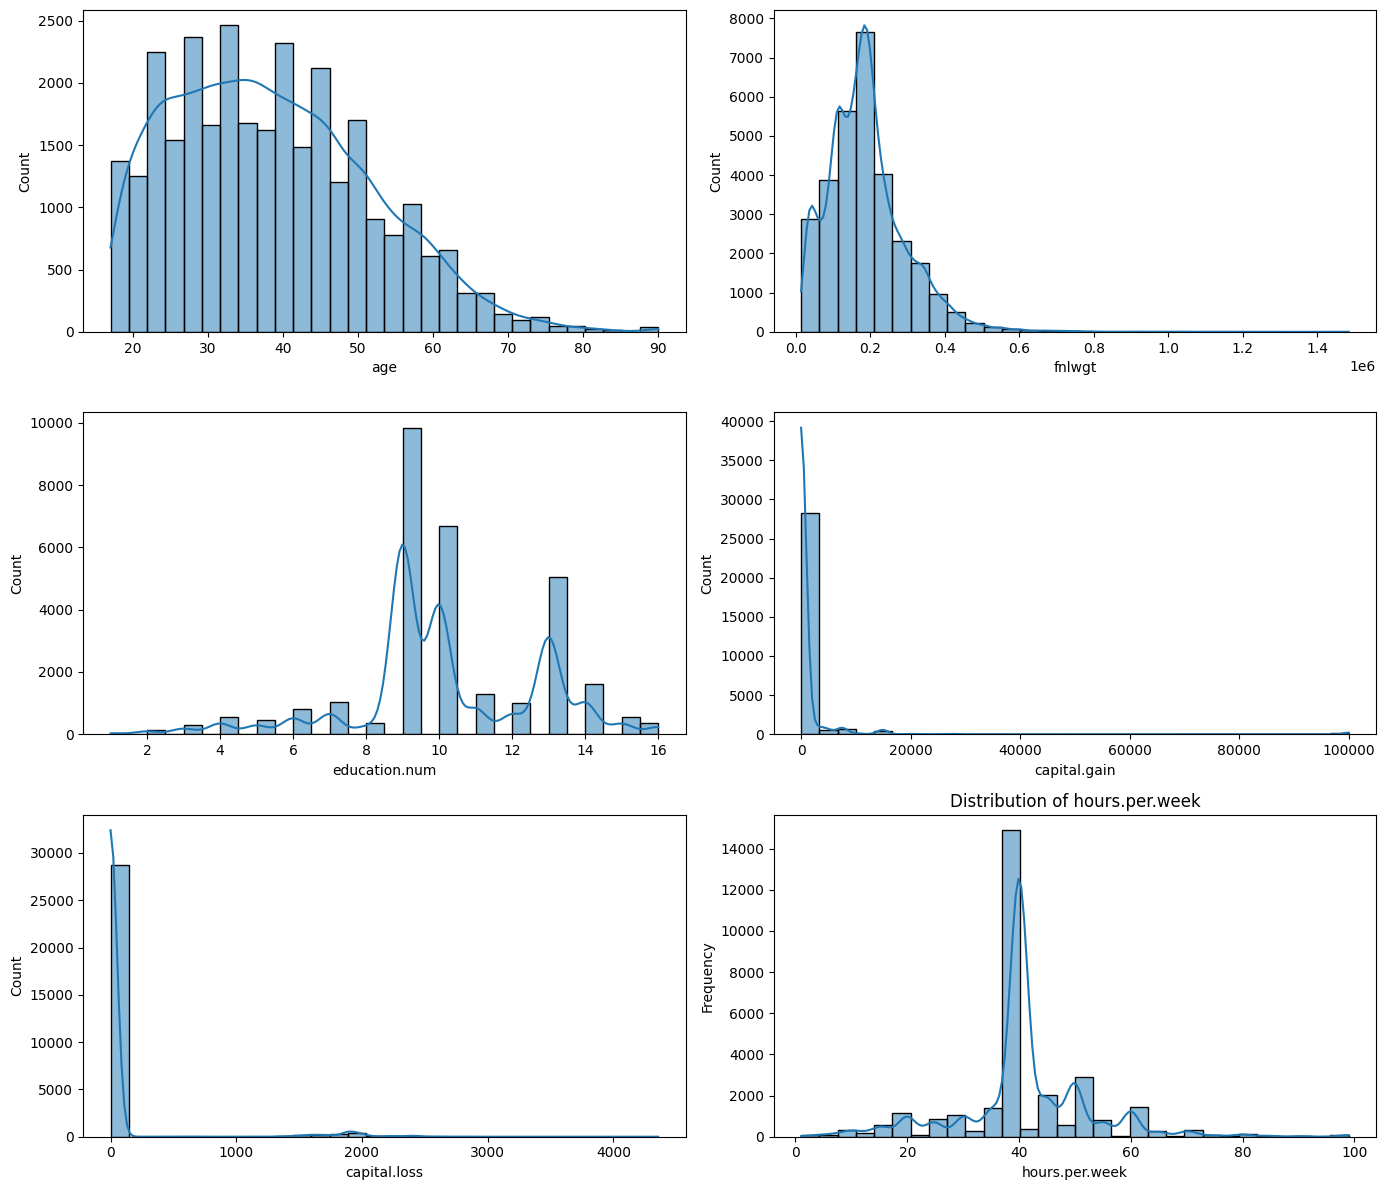

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for i, col in enumerate(numerical_features):
  ax = axes.flat[i]
  sns.histplot(data_copy[col], bins=30, kde=True, ax=ax)
  plt.title(f'Distribution of {col}')
  plt.xlabel(col)
  plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

### fnlwgt & education
- `fnlwgt` ("final weight")
  - it is a sampling weight assigned by the Census Bureau. It is the number of people in the population that each row represents, so it describes how the survey was sampled, not the individual person.
  - It has no real relationship with income, so we drop it.
- `education`
  - The education column will be removed because education.num provides a numerical representation of the same educational information.


In [ ]:
data_copy = data_copy.drop(columns=['fnlwgt', 'education'])
numerical_features.remove('fnlwgt')
categorical_features.remove('education')
print(data_copy.columns)
print(numerical_features)
print(categorical_features)

Index(['age', 'workclass', 'education.num', 'marital.status', 'occupation',
       'relationship', 'race', 'sex', 'capital.gain', 'capital.loss',
       'hours.per.week', 'native.country', 'income'],
      dtype='object')
['age', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']
['workclass', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country', 'income']


### capital.gain & capital.loss
- most the values of capital.gain & capital.loss are concentrated on zero
- we must consider zero here with the mean of none (not low), so the person with capital equal 1 doesn't mean that he has capital less than person with capital equals 0
- So, we can divide them into bins
  - none > the person has no any capital gain or loss
  - low > the person has low capital gain or loss
  - medium > the person has medium capital gain or loss
  - high > the person has high capital gain or loss

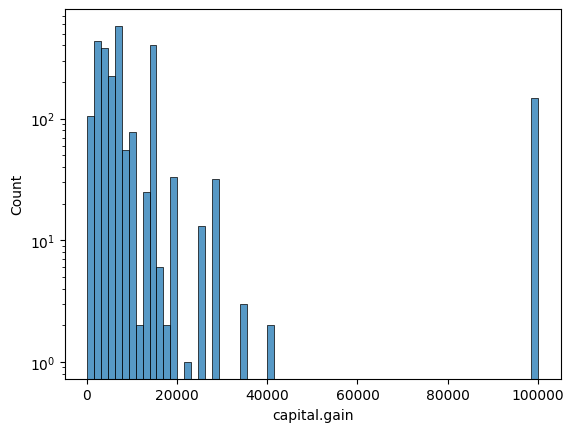

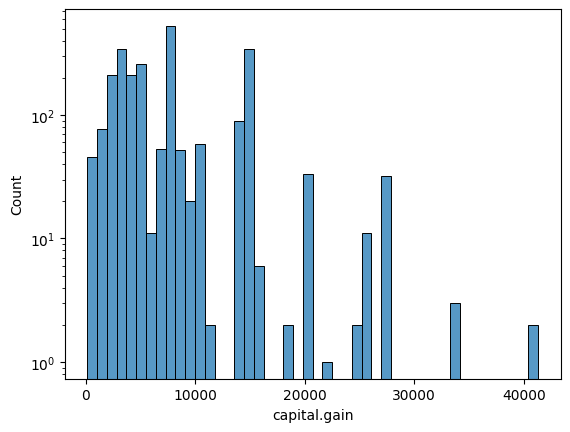

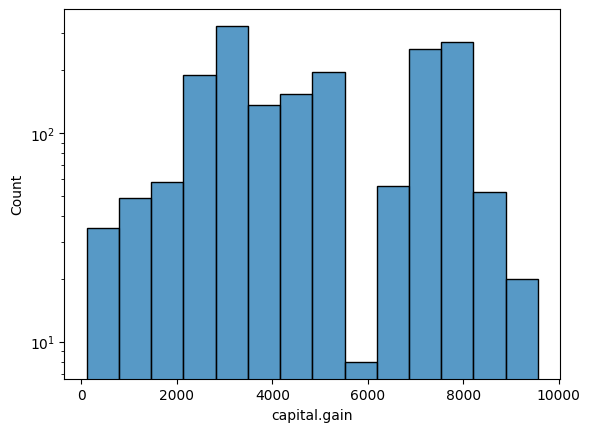

In [ ]:
with_captial_gain = data_copy[data_copy['capital.gain'] > 0]
sns.histplot(data=with_captial_gain['capital.gain'])
plt.yscale('log')
plt.show()
with_captial_gain = data_copy[(data_copy['capital.gain'] > 0) & (data_copy['capital.gain'] < 80000)]
sns.histplot(data=with_captial_gain['capital.gain'])
plt.yscale('log')
plt.show()
with_captial_gain = data_copy[(data_copy['capital.gain'] > 0) & (data_copy['capital.gain'] < 10000)]
sns.histplot(data=with_captial_gain['capital.gain'])
plt.yscale('log')
plt.show()

In [ ]:
bins= [-1, 0, 10000, 80000, np.inf]
labels = ['none', 'low', 'medium', 'high']
data_copy['capital.gain.level'] = pd.cut(data_copy['capital.gain'], bins=bins, labels=labels)
data_copy[['capital.gain', 'capital.gain.level']]

,capital.gain,capital.gain.level
0,0,none
1,0,none
2,0,none
3,0,none
4,0,none
...,...,...
30164,0,none
30165,0,none
30166,0,none
30167,0,none


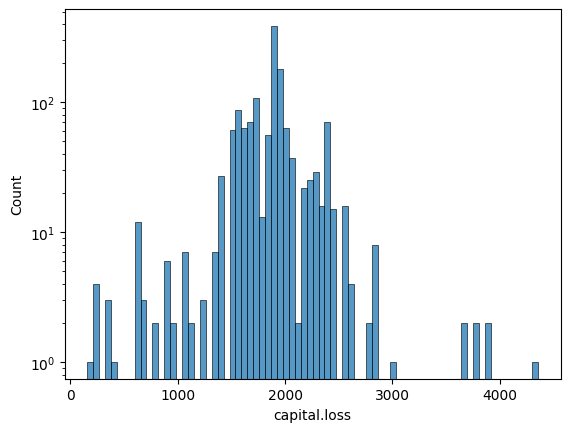

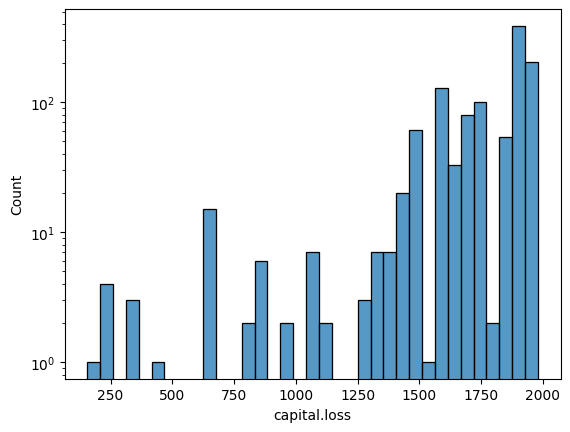

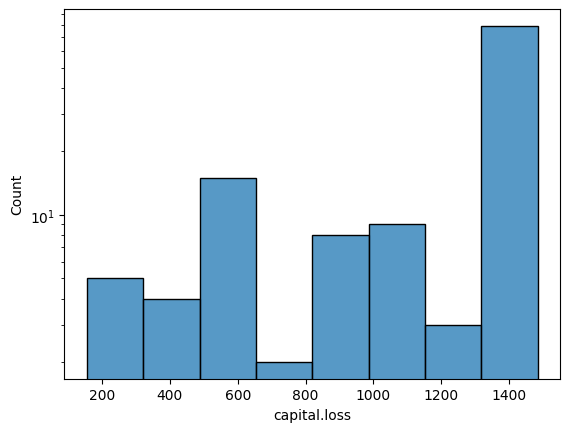

In [ ]:
with_captial_loss = data_copy[data_copy['capital.loss'] > 0]
sns.histplot(data=with_captial_loss['capital.loss'])
plt.yscale('log')
plt.show()
with_captial_loss = data_copy[(data_copy['capital.loss'] > 0) & (data_copy['capital.loss'] < 2000)]
sns.histplot(data=with_captial_loss['capital.loss'])
plt.yscale('log')
plt.show()
with_captial_loss = data_copy[(data_copy['capital.loss'] > 0) & (data_copy['capital.loss'] < 1500)]
sns.histplot(data=with_captial_loss['capital.loss'])
plt.yscale('log')
plt.show()

In [ ]:
bins= [-1, 0, 1500, 2000, np.inf]
labels = ['none', 'low', 'medium', 'high']
data_copy['capital.loss.level'] = pd.cut(data_copy['capital.loss'], bins=bins, labels=labels)
data_copy[['capital.loss', 'capital.loss.level']]

,capital.loss,capital.loss.level
0,4356,high
1,3900,high
2,3900,high
3,3770,high
4,3770,high
...,...,...
30164,0,none
30165,0,none
30166,0,none
30167,0,none


In [ ]:
data_copy = data_copy.drop(columns=['capital.gain', 'capital.loss'])
print(data_copy.columns)
numerical_features = [c for c in numerical_features if c not in ['capital.gain', 'capital.loss']]
print(numerical_features)
categorical_features.extend(['capital.gain.level', 'capital.loss.level'])
print(categorical_features)

Index(['age', 'workclass', 'education.num', 'marital.status', 'occupation',
       'relationship', 'race', 'sex', 'hours.per.week', 'native.country',
       'income', 'capital.gain.level', 'capital.loss.level'],
      dtype='object')
['age', 'education.num', 'hours.per.week']
['workclass', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country', 'income', 'capital.gain.level', 'capital.loss.level']


## Correlation between Numerical Features

In [ ]:
corr_matrix = data_copy[numerical_features].corr()
corr_matrix

,age,education.num,hours.per.week
age,1.000000,0.043848,0.101917
education.num,0.043848,1.000000,0.152650
hours.per.week,0.101917,0.152650,1.000000


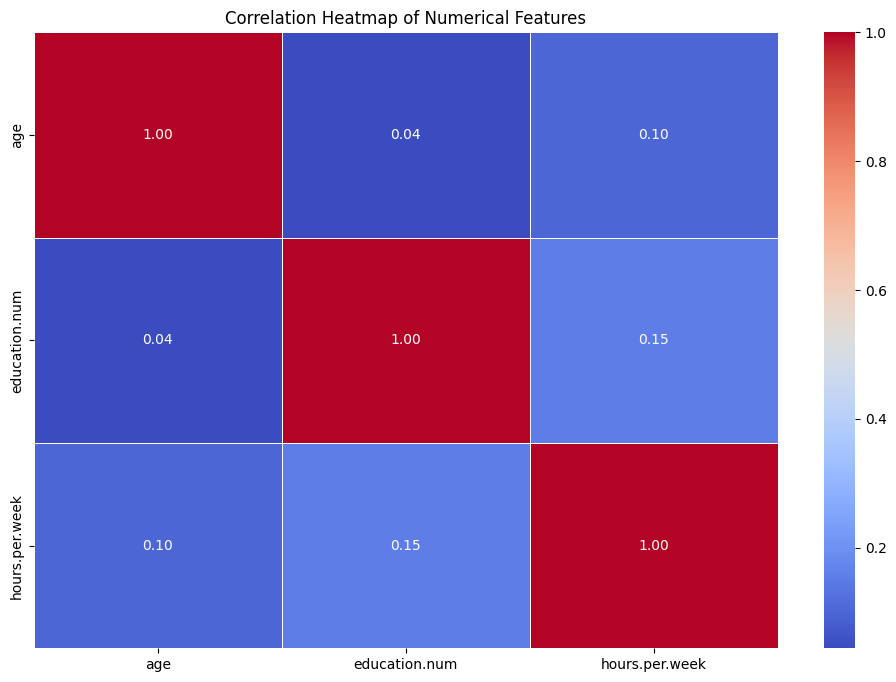

In [ ]:
plt.figure(figsize=(12, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

Grouping rare categories with fewer than 50 occurrences in the training set into an Other category before applying One-Hot Encoding.

In [ ]:
country_counts = data_copy['native.country'].value_counts()
rare_countries = country_counts[country_counts < 50].index
print(rare_countries)

Index(['Taiwan', 'Haiti', 'Iran', 'Portugal', 'Nicaragua', 'Peru', 'Greece',
       'Ecuador', 'France', 'Ireland', 'Hong', 'Trinadad&Tobago', 'Cambodia',
       'Thailand', 'Laos', 'Yugoslavia', 'Outlying-US(Guam-USVI-etc)',
       'Hungary', 'Honduras', 'Scotland', 'Holand-Netherlands'],
      dtype='object', name='native.country')


In [ ]:
data_copy['native.country'] = data_copy['native.country'].replace(
    rare_countries, 'Other'
)

In [ ]:
print(data_copy['native.country'].unique())
print(data_copy['native.country'].value_counts())

['United-States' 'Mexico' 'Other' 'Vietnam' 'China' 'India' 'Philippines'
 'Canada' 'South' 'Puerto-Rico' 'Poland' 'England' 'Germany' 'Italy'
 'Japan' 'Cuba' 'Dominican-Republic' 'Columbia' 'Guatemala' 'El-Salvador'
 'Jamaica']
native.country
United-States         27511
Mexico                  610
Other                   486
Philippines             188
Germany                 128
Puerto-Rico             109
Canada                  107
India                   100
El-Salvador             100
Cuba                     92
England                  86
Jamaica                  80
South                    71
Italy                    68
China                    68
Dominican-Republic       67
Vietnam                  64
Guatemala                63
Japan                    59
Poland                   56
Columbia                 56
Name: count, dtype: int64


# Model Pipline and Fine Tuning

### Train-Test Split and Target Distribution

The dataset was split into training and testing sets using stratified sampling.

- Training set: 80%
- Testing set: 20%
- Random state: 42
- Stratification was applied using the target variable `income`.

**Results:**

The class distribution remained almost identical in both sets:

- Training: 75.11% (<=50K), 24.89% (>50K).
- Testing: 75.10% (<=50K), 24.89% (>50K).

**Conclusion:**

Stratified splitting successfully preserved the original target distribution in both datasets. However, the class imbalance still exists and may require further investigation during model evaluation.

### One-Hot Encoding Results

- Categorical features were successfully converted into numerical representations using One-Hot Encoding.
- The `education` column was removed because `education.num` provides similar educational information.
- Rare categories in `native.country` were grouped into an `Other` category based on the training set.
- `drop='first'` was used to avoid the dummy variable trap.
- `handle_unknown='ignore'` was used to handle unseen categories in the testing set.

**Results:**
- Training set: 26,029 samples and 60 features.
- Testing set: 6,508 samples and 60 features.
- No categorical columns remain.
- Both datasets have identical feature columns.

**Conclusion:** One-Hot Encoding was successfully applied without introducing inconsistencies between training and testing sets.

### Comparison of Scaling and Transformation Techniques

Three techniques were explored to improve the numerical features:

**1. RobustScaler**
- Uses the median and interquartile range (IQR) for scaling.
- Is less sensitive to extreme values than StandardScaler.
- Centers the median around zero and scales the IQR.
- Extreme values remain present but have less influence on the scaling parameters.

**2. StandardScaler**
- Transforms features to have approximately zero mean and unit standard deviation.
- Makes numerical features comparable in scale.
- Is sensitive to outliers, which is noticeable in features such as `fnlwgt`, `capital.gain`, and `capital.loss`.

**3. Log Transformation**
- Applied `np.log1p()` to `capital.gain` and `capital.loss`.
- Reduces the impact of large values and compresses the right-skewed distributions.
- The median and 75th percentile remain zero because most observations have zero values.
- Does not eliminate skewness completely.

**Overall Conclusion:**

RobustScaler is a promising scaling option because the dataset contains extreme values. Log Transformation can also help reduce the skewness of `capital.gain` and `capital.loss`.

The final choice of preprocessing techniques should be based on comparing model performance using cross-validation rather than relying only on descriptive statistics.

In [ ]:
X = data_copy.drop(columns=['income'])
y = data_copy['income']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y)
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(24135, 12)
(24135,)
(6034, 12)
(6034,)


In [ ]:
print(data_copy['income'].value_counts(normalize=True) * 100)
print(y_train.value_counts(normalize=True) * 100)
print(y_test.value_counts(normalize=True) * 100)

income
<=50K    75.113527
>50K     24.886473
Name: proportion, dtype: float64
income
<=50K    75.114978
>50K     24.885022
Name: proportion, dtype: float64
income
<=50K    75.107723
>50K     24.892277
Name: proportion, dtype: float64


In [ ]:
categorical_features_for_training = [f for f in categorical_features if f != 'income']
preprocessor = ColumnTransformer([
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features_for_training),
        ('scaler', RobustScaler(), numerical_features),
])

In [ ]:
encoder = LabelEncoder()
y_train = encoder.fit_transform(y_train)
y_test = encoder.transform(y_test)

# Model Pipline and fine tuning

In [ ]:
models = {
    "LogReg": LogisticRegression(max_iter=1000, class_weight='balanced'),
    "SVM": SVC(),
    "KNN": KNeighborsClassifier(),
    "NaiveBayes": GaussianNB()
}

In [ ]:
param_grids = {
    "LogReg": [
        {"model__solver": ["lbfgs"],
         "model__penalty": ["l2"],
         "model__C": [0.001, 0.01, 0.1, 1, 10, 100]},
        {"model__solver": ["liblinear"],
         "model__penalty": ["l1", "l2"],
         "model__C": [0.001, 0.01, 0.1, 1, 10, 100]},
    ],
    "SVM":{
     "model__kernel": ["rbf"],
     "model__C": [0.1, 1, 10],
     "model__gamma": ["scale", 0.01, 0.1],
     "model__class_weight": [None, "balanced"]
     },
    "KNN": {
        "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2],
    },
    "NaiveBayes": {
        "model__var_smoothing": [1e-11, 1e-9, 1e-7, 1e-5, 1e-3],
    },
}

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model),
    ])

    grid = GridSearchCV(
        pipeline,
        param_grids.get(name, {}),
        cv=cv,
        scoring="f1",
        n_jobs=-1,
        verbose=1,
    )
    grid.fit(X_train, y_train)

    results[name] = {
        "estimator": grid.best_estimator_,
        "cv_score": grid.best_score_,
        "params": grid.best_params_,
    }
    print(f"{name}: {grid.best_score_:.4f}  {grid.best_params_}")

Fitting 5 folds for each of 18 candidates, totalling 90 fits
LogReg: 0.6830  {'model__C': 10, 'model__penalty': 'l2', 'model__solver': 'lbfgs'}
Fitting 5 folds for each of 18 candidates, totalling 90 fits
SVM: 0.6824  {'model__C': 1, 'model__class_weight': 'balanced', 'model__gamma': 0.1, 'model__kernel': 'rbf'}
Fitting 5 folds for each of 28 candidates, totalling 140 fits
KNN: 0.6463  {'model__n_neighbors': 21, 'model__p': 1, 'model__weights': 'uniform'}
Fitting 5 folds for each of 5 candidates, totalling 25 fits
NaiveBayes: 0.6458  {'model__var_smoothing': 0.001}


In [ ]:
summary = pd.DataFrame(
    {k: {"cv_f1": v["cv_score"]} for k, v in results.items()}
).T.sort_values("cv_f1", ascending=False)
print(summary)

best_name = summary.index[0]
best_model = results[best_name]["estimator"]
y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred))

               cv_f1
LogReg      0.683029
SVM         0.682379
KNN         0.646348
NaiveBayes  0.645838
              precision    recall  f1-score   support

           0       0.94      0.78      0.85      4532
           1       0.56      0.84      0.67      1502

    accuracy                           0.80      6034
   macro avg       0.75      0.81      0.76      6034
weighted avg       0.84      0.80      0.81      6034

